#  Exploratory Data Analysis  RACE Dataset
### Intelligent Reading Comprehension & Quiz Generation System

---

This notebook walks through a complete EDA of the **RACE dataset** 

> **Dataset splits:** Train / Dev / Test

## 1.  Import Libraries

In [1]:
import os
import string
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 2.  Load the Dataset

In [2]:
train_df = pd.read_csv('../data/raw/train.csv')

print(f"Train : {train_df.shape}")

Train : (87866, 9)


## 3.  Basic Data Inspection

In [3]:
train_df.head()

,Unnamed: 0,id,article,question,A,B,C,D,answer
0,0,middle7348.txt,In the summer between my first year and second...,Before the writer came to the high school summ...,instructor,camper,student,reporter,C
1,1,middle7348.txt,In the summer between my first year and second...,How many times did the writer invite the boy t...,Once,Twice,Three times,Many times,B
2,2,middle4305.txt,A bumpkin went to a big city for the first t...,The bumpkin thought _ .,his wife was as beautiful as the young girl,his wife was more beautiful than the short fat...,the short fat woman changed to a young girl in...,He should also buy a room of that kind for his...,C
3,3,middle4305.txt,A bumpkin went to a big city for the first t...,The room he saw was perhaps _ .,an office,a toilet,a lift,a helicopter,C
4,4,middle4305.txt,A bumpkin went to a big city for the first t...,We can see that the bumpkin had no knowledge ...,farming or gardening,how to do farm work,how to live in a city,modern city life,D


In [4]:
train_df.dtypes

Unnamed: 0    int64
id              str
article         str
question        str
A               str
B               str
C               str
D               str
answer          str
dtype: object

## 4.  Data Quality Checks

In [5]:
# Missing values per column
train_df.isnull().sum()

Unnamed: 0    0
id            0
article       0
question      0
A             4
B             0
C             1
D             9
answer        0
dtype: int64

In [6]:
# Duplicate rows
print(f"Duplicate rows: {train_df.duplicated().sum()}")

Duplicate rows: 0


## 5.  Feature Engineering 

In [7]:
train_df['article_word_count'] = train_df['article'].astype(str).apply(lambda x: len(x.split()))
train_df['question_word_count'] = train_df['question'].astype(str).apply(lambda x: len(x.split()))

## 6.  Passage Length Distribution

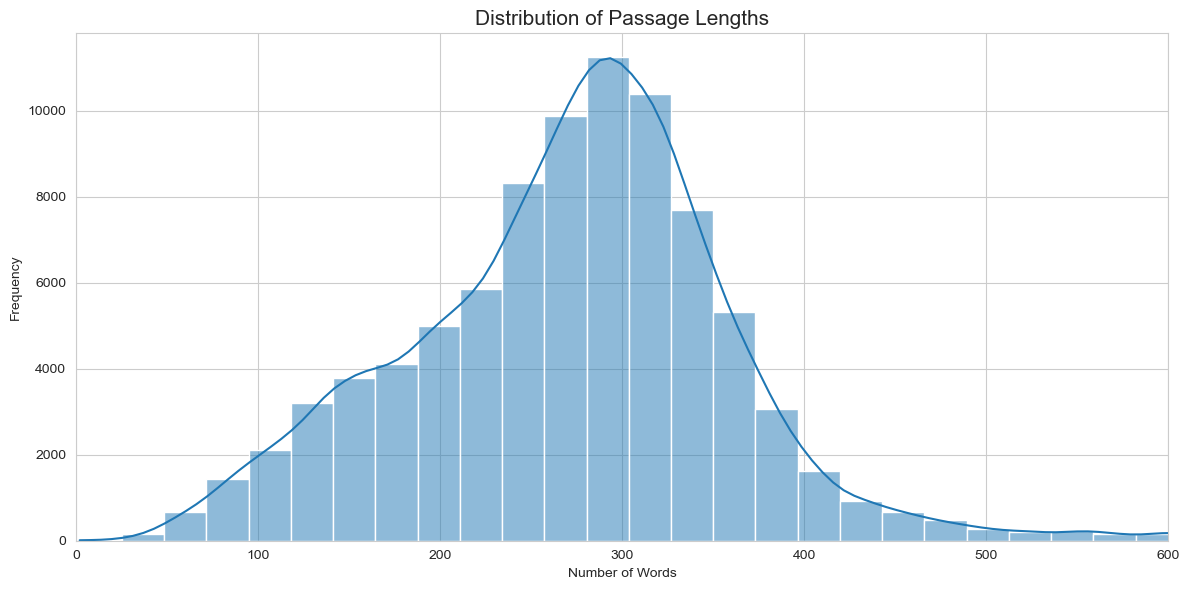

In [8]:
plt.figure(figsize=(12, 6))

sns.histplot(train_df['article_word_count'], bins=50, kde=True)

plt.title('Distribution of Passage Lengths', fontsize=15)
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.xlim(0, 600)

plt.tight_layout()
plt.show()

## 7.  Question Length Distribution

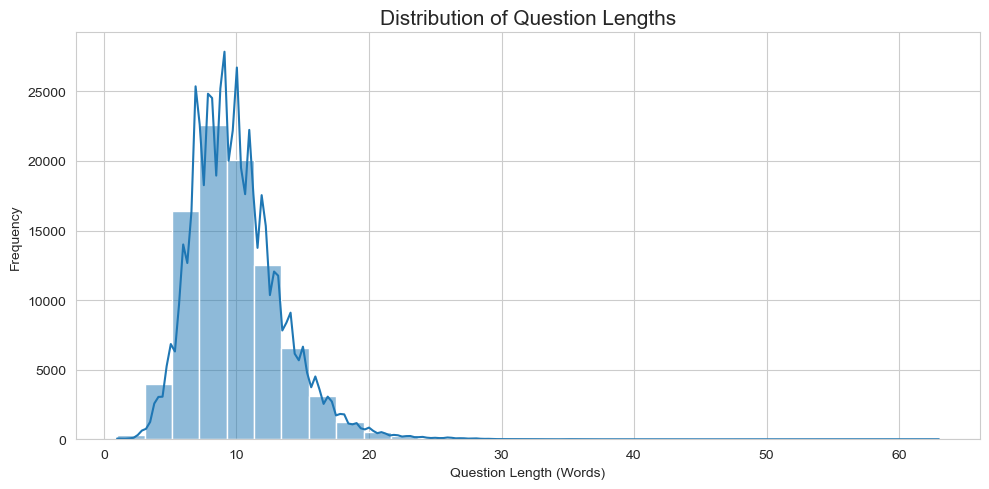

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(train_df['question_word_count'], bins=30, kde=True)

plt.title('Distribution of Question Lengths', fontsize=15)
plt.xlabel('Question Length (Words)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

## 8.  Answer Class Distribution

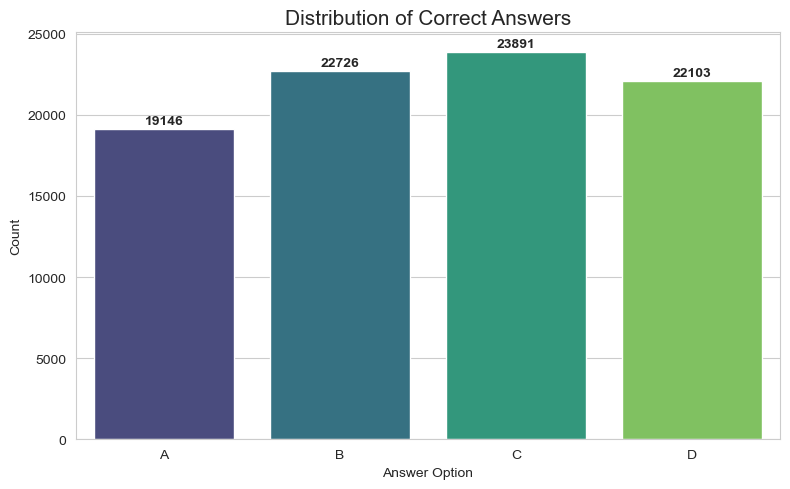

In [10]:
answer_counts = train_df['answer'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=answer_counts.index,
    y=answer_counts.values,
    hue=answer_counts.index,
    palette='viridis',
    legend=False
)

plt.title('Distribution of Correct Answers', fontsize=15)
plt.xlabel('Answer Option')
plt.ylabel('Count')

for i, v in enumerate(answer_counts.values):
    plt.text(i, v + 300, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 9.  Question Type Analysis

C:\Users\Zohaib Umer\AppData\Local\Temp\ipykernel_21252\4025617697.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=type_counts.values, y=type_counts.index, palette='magma')


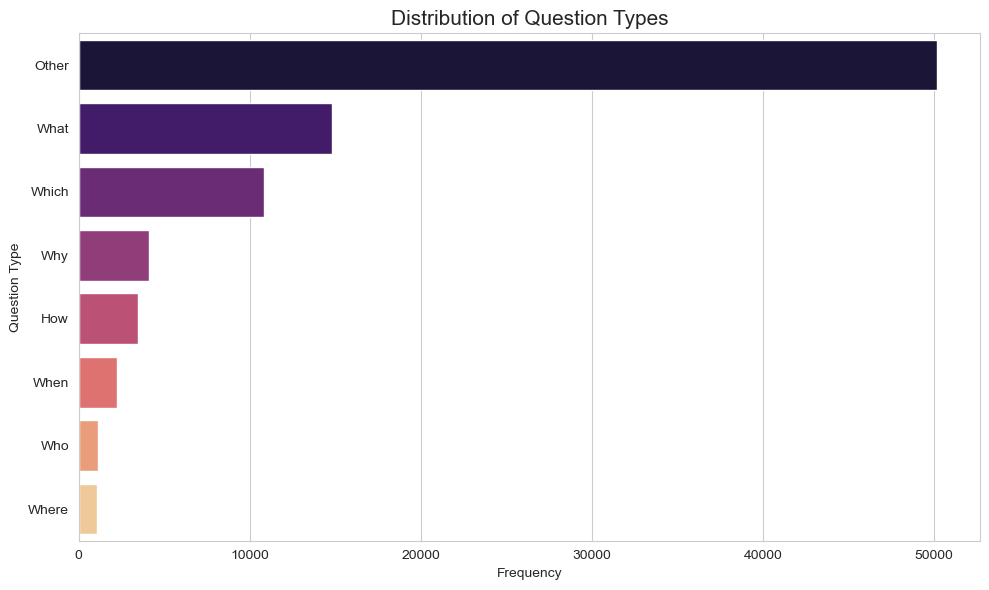

In [11]:
def categorize_question(text):
    """Map a question to its type based on the first word."""
    text = str(text).lower().strip()

    if not text.split():
        return "Other"

    first_word = text.split()[0]

    mapping = {
        "what": "What",
        "why": "Why",
        "how": "How",
        "who": "Who",
        "where": "Where",
        "when": "When",
        "which": "Which"
    }

    return mapping.get(first_word, "Other")


train_df['question_type'] = train_df['question'].apply(categorize_question)

type_counts = train_df['question_type'].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(x=type_counts.values, y=type_counts.index, palette='magma')

plt.title('Distribution of Question Types', fontsize=15)
plt.xlabel('Frequency')
plt.ylabel('Question Type')

plt.tight_layout()
plt.show()

## 10.  Summary Statistics

In [12]:
summary_stats = train_df[['article_word_count', 'question_word_count']].describe().round(2)

summary_stats.columns = ['Passage Length (Words)', 'Question Length (Words)']

summary_stats

,Passage Length (Words),Question Length (Words)
count,87866.00,87866.00
mean,274.98,10.01
std,97.88,3.38
min,2.00,1.00
25%,217.00,8.00
50%,279.00,10.00
75%,326.00,12.00
max,1162.00,63.00


## 11. Top 20 Most Frequent Words in Articles

C:\Users\Zohaib Umer\AppData\Local\Temp\ipykernel_21252\919080245.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=common_df, x='Frequency', y='Word', palette='coolwarm')


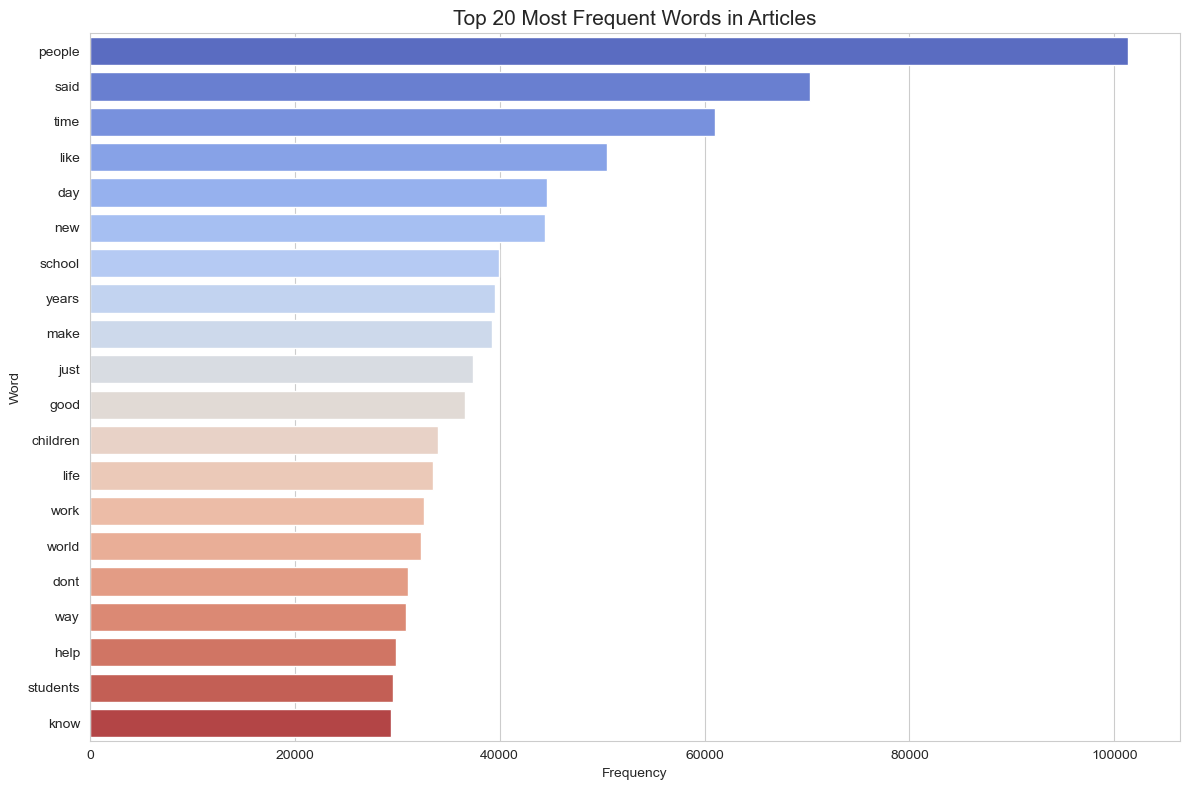

In [13]:
all_text = " ".join(train_df['article'].astype(str)).lower()
all_text = all_text.translate(str.maketrans('', '', string.punctuation))

words = all_text.split()

# Filter out common stopwords and very short tokens
filtered_words = [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 2]

common_words = Counter(filtered_words).most_common(20)

common_df = pd.DataFrame(common_words, columns=['Word', 'Frequency'])

plt.figure(figsize=(12, 8))

sns.barplot(data=common_df, x='Frequency', y='Word', palette='coolwarm')

plt.title('Top 20 Most Frequent Words in Articles', fontsize=15)
plt.tight_layout()
plt.show()

## 12.  Feature Correlation Heatmap

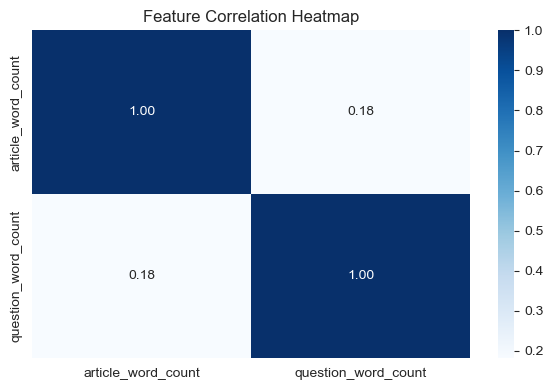

In [14]:
corr = train_df[['article_word_count', 'question_word_count']].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f')

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## 13.  Correct Answer Distribution — Pie Chart


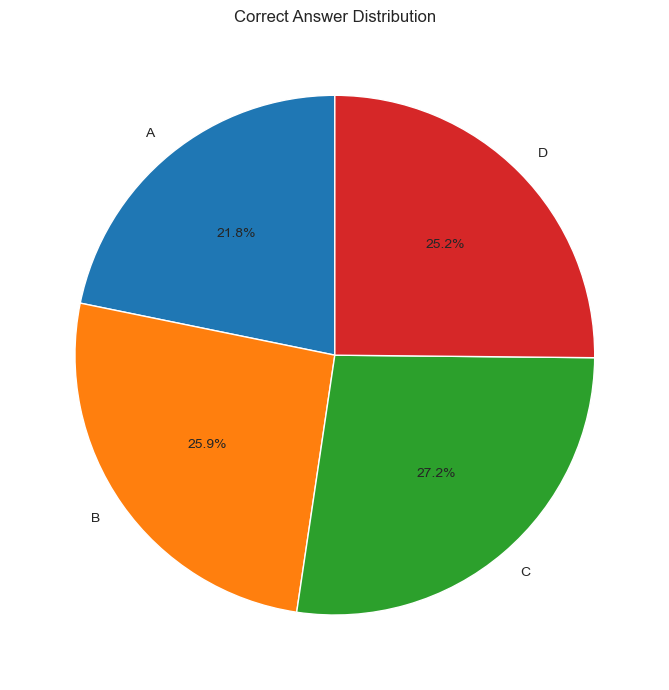

In [15]:
plt.figure(figsize=(7, 7))

plt.pie(
    answer_counts.values,
    labels=answer_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Correct Answer Distribution')
plt.tight_layout()
plt.show()

## 14. Save Processed Features

In [16]:
os.makedirs('../data/processed', exist_ok=True)

train_df.to_csv('../data/processed/train_eda_processed.csv', index=False)

print("Processed file saved to: ../data/processed/train_eda_processed.csv")

Processed file saved to: ../data/processed/train_eda_processed.csv
